# Modellierung

## Init

In [54]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from xgboost import XGBRegressor
from sklearn.neural_network import MLPRegressor

# Load the dataset
file_path = '../../data/processed/sickness_table.csv'
df = pd.read_csv(file_path, index_col=0)

# Convert date column to datetime
df['date'] = pd.to_datetime(df['date'])

# Datenselektierung

In [55]:
df

,date,n_sick,calls,n_duty,n_sby,sby_need,dafted,is_holiday,month,day_of_week,...,n_sick_ma_14,calls_ma_21,n_sick_ma_21,calls_ma_7_lag_30,n_sick_ma_7_lag_30,calls_ma_14_lag_30,n_sick_ma_14_lag_30,calls_ma_21_lag_30,n_sick_ma_21_lag_30,season
0,2016-04-01,73,8154.0,1700,90,4.0,0.0,False,4,4,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1
1,2016-04-02,64,8526.0,1700,90,70.0,0.0,False,4,5,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1
2,2016-04-03,68,8088.0,1700,90,0.0,0.0,False,4,6,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1
3,2016-04-04,71,7044.0,1700,90,0.0,0.0,False,4,0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1
4,2016-04-05,63,7236.0,1700,90,0.0,0.0,False,4,1,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1147,2019-05-23,86,8544.0,1900,90,0.0,0.0,False,5,3,...,78.714286,9793.714286,77.047619,9396.857143,80.000000,9228.000000,74.571429,9428.285714,73.285714,1
1148,2019-05-24,81,8814.0,1900,90,0.0,0.0,False,5,4,...,78.785714,9654.285714,77.380952,9628.285714,82.571429,9231.857143,76.214286,9398.000000,73.857143,1
1149,2019-05-25,76,9846.0,1900,90,146.0,56.0,False,5,5,...,79.285714,9583.428571,77.857143,9534.000000,82.714286,9219.428571,77.214286,9331.428571,74.190476,1
1150,2019-05-26,83,9882.0,1900,90,160.0,70.0,False,5,6,...,79.642857,9575.714286,78.238095,9422.571429,82.571429,9239.142857,77.857143,9288.000000,74.809524,1


In [62]:

# List der Spalten, die nicht benutzt werden sollen, da sie u. a. zur Anwendungszeit nicht zur Verfügung stehen und daher auch nicht als Features genutzt werden können oder
excluded_columns = ["sby_need", "dafted", "n_sick", "calls", "call_stress", "sby_used_percent", "calls_per_duty", "date", "calls_ma_7", "n_sick_ma_7", "calls_ma_14", "n_sick_ma_14", "calls_ma_21", "n_sick_ma_21", "unix_ts_date"]

usable_columns = list(set(df.columns) - set(excluded_columns))

target_column = 'sby_need'

print(usable_columns)

['is_weekend', 'n_sick_ma_14_lag_30', 'n_duty', 'day_of_week', 'week_of_year', 'is_holiday', 'calls_ma_21_lag_30', 'season', 'n_sick_ma_7_lag_30', 'calls_ma_14_lag_30', 'n_sick_ma_21_lag_30', 'month', 'n_sby', 'calls_ma_7_lag_30']


In [63]:
# Prepare features and target
X = df[usable_columns]

#X = df[['n_duty', 'season', 'month', 'day_of_week', 'is_holiday', 'is_weekend']] #auf faktoren beschränkt, die man zu dem Zeitpunkt der Planung wissen kann

y = df[target_column]

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Modellierungvergleiche

In [64]:
# Initialize models
models = {
    'StackingRegressor' : StackingRegressor(estimators=[
            ('lr', LinearRegression()),
            ('dt', DecisionTreeRegressor()),
            ('svr', SVR())
        ], 
    final_estimator=Ridge()),
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'Support Vector Machine': SVR(),
    'K-Nearest Neighbors': KNeighborsRegressor(),
    'Neural Network': MLPRegressor(random_state=42, max_iter=1000),
    'Lasso Regression': Lasso(random_state=42),
    'Ridge Regression': Ridge(random_state=42),
    'XGBoost': XGBRegressor(random_state=42)
}

# Train and evaluate each model
results = {}
for model_name, model in models.items():
    start_time = time.time()
    model.fit(X_train, y_train)
    end_time = time.time() 

    training_time = end_time - start_time
    y_pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    results[model_name] = {'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2': r2, "Training Time" : training_time}
    print(f'{model_name} - MAE: {mae}, MSE: {mse}, RMSE: {rmse}, R2: {r2}, "Training Time (s)" : {training_time}')


StackingRegressor - MAE: 40.71119196196198, MSE: 3442.775661688444, RMSE: 58.675170742729364, R2: 0.09078818136892886, "Training Time (s)" : 0.18069171905517578
Linear Regression - MAE: 42.892126576320436, MSE: 3803.9830126522274, RMSE: 61.676438067160035, R2: -0.004604032572663952, "Training Time (s)" : 0.0015158653259277344
Decision Tree - MAE: 39.32900432900433, MSE: 6709.225108225109, RMSE: 81.90985965209016, R2: -0.7718571762131357, "Training Time (s)" : 0.006201505661010742
Random Forest - MAE: 36.16506493506494, MSE: 3493.8198281385285, RMSE: 59.10854276784811, R2: 0.07730779113466435, "Training Time (s)" : 0.40929174423217773
Gradient Boosting - MAE: 37.0784907946511, MSE: 3271.037006158742, RMSE: 57.19298039234135, R2: 0.13614310154599207, "Training Time (s)" : 0.18443965911865234
Support Vector Machine - MAE: 24.611666533714203, MSE: 4384.751151221588, RMSE: 66.2174535241396, R2: -0.15798064126306666, "Training Time (s)" : 0.027355194091796875
K-Nearest Neighbors - MAE: 38.23

Models sorted by MAE:


,MAE,MSE,RMSE,R2,Training Time
Gradient Boosting,37.078491,3271.037006,57.192980,0.136143,0.184440
Neural Network,35.596204,3311.750819,57.547813,0.125391,0.175272
StackingRegressor,40.711192,3442.775662,58.675171,0.090788,0.180692
Random Forest,36.165065,3493.819828,59.108543,0.077308,0.409292
Lasso Regression,42.172355,3635.683129,60.296626,0.039843,0.010688
Ridge Regression,42.881710,3800.370742,61.647147,-0.003650,0.001470
Linear Regression,42.892127,3803.983013,61.676438,-0.004604,0.001516
K-Nearest Neighbors,38.236364,3818.484675,61.793889,-0.008434,0.001464
XGBoost,36.672421,3980.080535,63.087879,-0.051110,0.055061
Support Vector Machine,24.611667,4384.751151,66.217454,-0.157981,0.027355


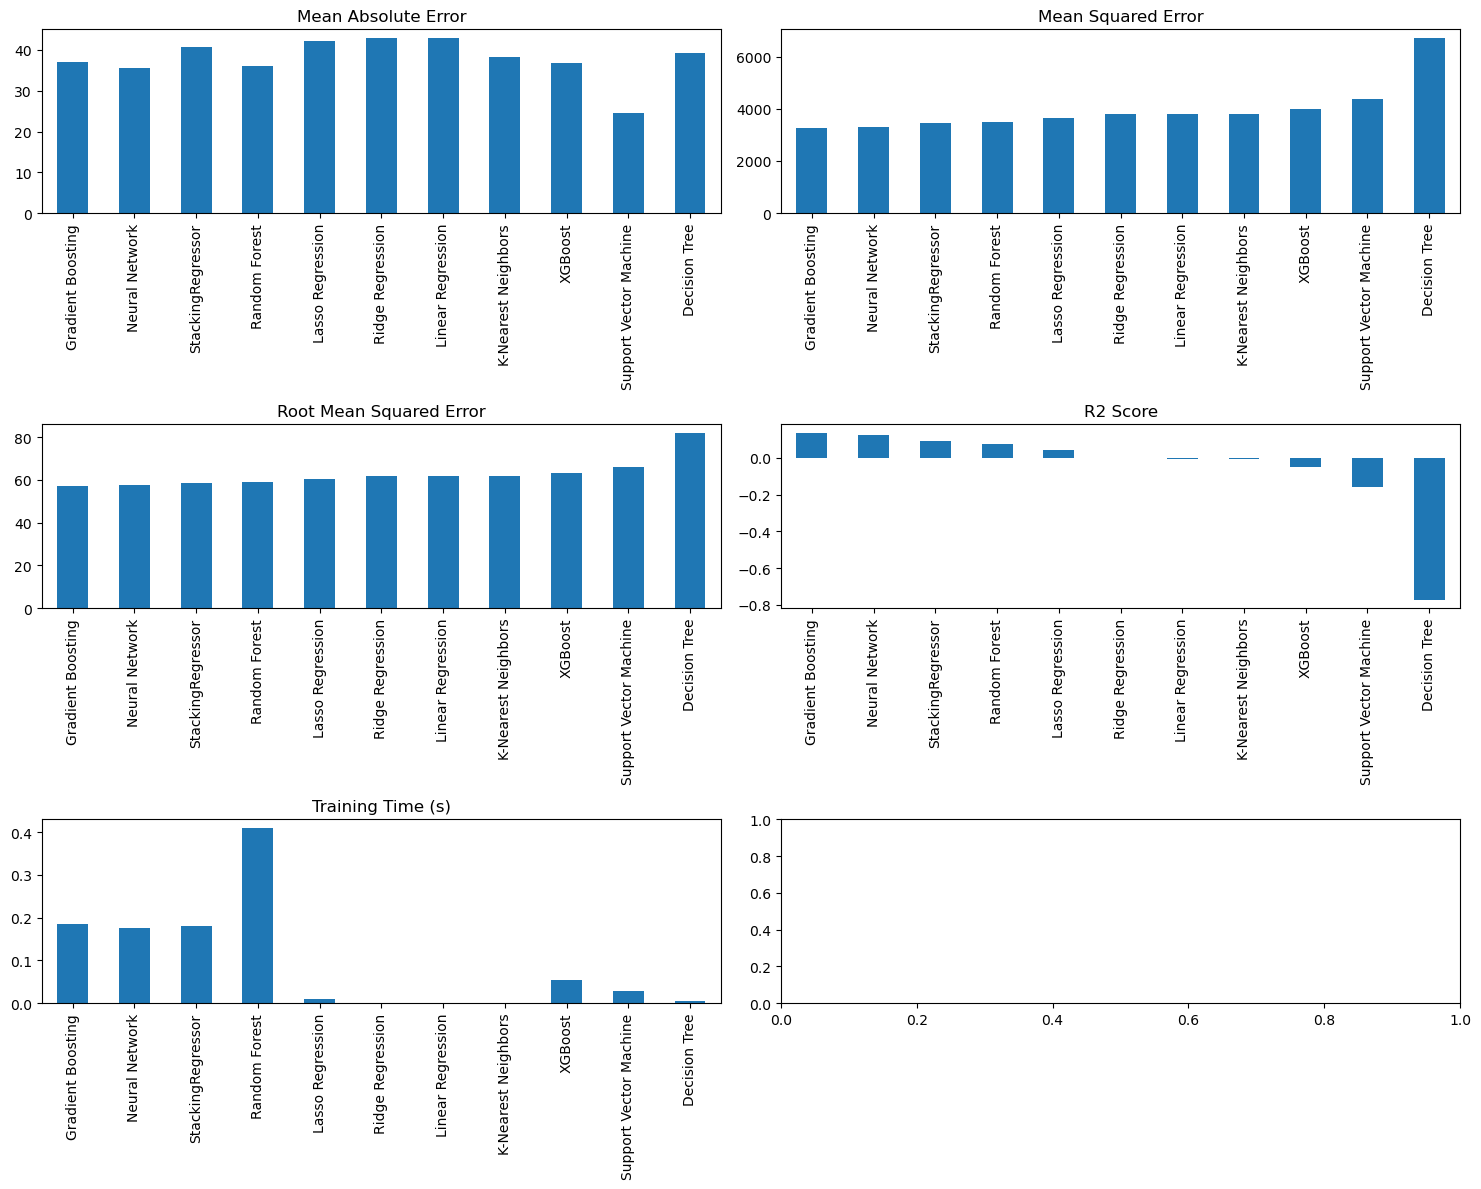

In [65]:
# Convert results to a DataFrame for easier comparison
results_df = pd.DataFrame(results).T

# Sort the models by MAE (you can change the metric to sort by other scores)
results_df_sorted = results_df.sort_values(by='R2', ascending=False)

print("Models sorted by MAE:")
display(results_df_sorted)

# Visualize the results
fig, axes = plt.subplots(3, 2, figsize=(15, 12))
results_df_sorted['MAE'].plot(kind='bar', ax=axes[0, 0], title='Mean Absolute Error')
results_df_sorted['MSE'].plot(kind='bar', ax=axes[0, 1], title='Mean Squared Error')
results_df_sorted['RMSE'].plot(kind='bar', ax=axes[1, 0], title='Root Mean Squared Error')
results_df_sorted['R2'].plot(kind='bar', ax=axes[1, 1], title='R2 Score')
results_df_sorted['Training Time'].plot(kind='bar', ax=axes[2, 0], title='Training Time (s)')
plt.tight_layout()
plt.show()

In [66]:
# Select the best model based on MAE
best_model_name = results_df_sorted.index[0]
best_model_results = results_df_sorted.loc[best_model_name]

print(f'Best Model: {best_model_name}')
print(best_model_results)

Best Model: Gradient Boosting
MAE                37.078491
MSE              3271.037006
RMSE               57.192980
R2                  0.136143
Training Time       0.184440
Name: Gradient Boosting, dtype: float64


Final Evaluation of the Best Model (Gradient Boosting):
MAE: 37.0784907946511, MSE: 3271.037006158742, RMSE: 57.19298039234135, R2: 0.13614310154599207


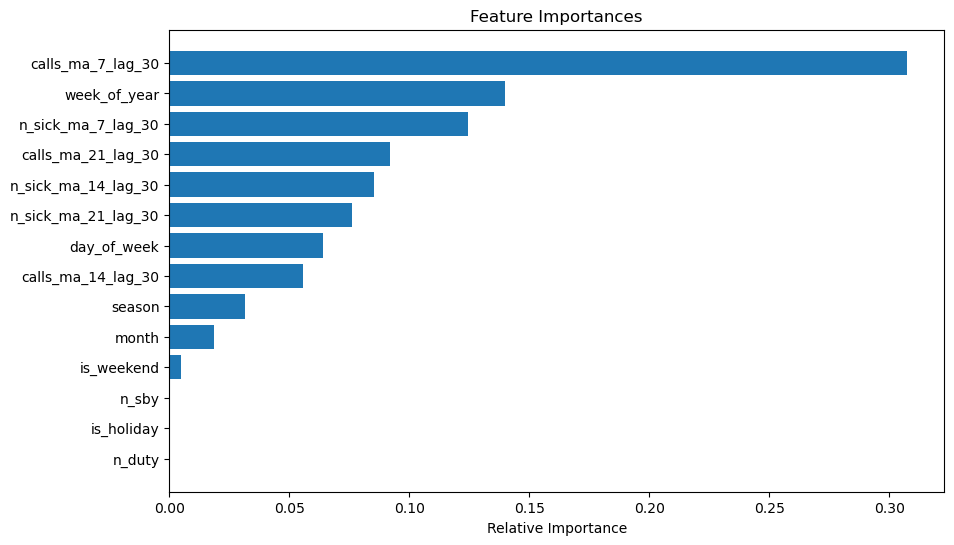

In [67]:
# If further fine-tuning is needed, you can perform hyperparameter tuning on the best model
if best_model_name == 'Random Forest':
    param_grid = {
        'n_estimators': [100, 200],
        'max_depth': [10, 20, None],
        'min_samples_split': [2, 5]
    }
    grid_search = GridSearchCV(RandomForestRegressor(random_state=42), param_grid, cv=5, scoring='neg_mean_absolute_error')
    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_
elif best_model_name == 'Gradient Boosting':
    param_grid = {
        'n_estimators': [100, 200],
        'learning_rate': [0.01, 0.1, 0.2],
        'max_depth': [3, 5, 7]
    }
    grid_search = GridSearchCV(GradientBoostingRegressor(random_state=42), param_grid, cv=5, scoring='neg_mean_absolute_error')
    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_
elif best_model_name == 'XGBoost':
    param_grid = {
        'n_estimators': [100, 200],
        'learning_rate': [0.01, 0.1, 0.2],
        'max_depth': [3, 5, 7]
    }
    grid_search = GridSearchCV(XGBRegressor(random_state=42), param_grid, cv=5, scoring='neg_mean_absolute_error')
    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_
# Add similar tuning for other models if needed

# Train the best model with the entire dataset
best_model.fit(X_train, y_train)
y_pred_best = best_model.predict(X_test)

# Final evaluation of the best model
final_mae = mean_absolute_error(y_test, y_pred_best)
final_mse = mean_squared_error(y_test, y_pred_best)
final_rmse = np.sqrt(final_mse)
final_r2 = r2_score(y_test, y_pred_best)

print(f'Final Evaluation of the Best Model ({best_model_name}):')
print(f'MAE: {final_mae}, MSE: {final_mse}, RMSE: {final_rmse}, R2: {final_r2}')


# Feature Importance for the best model
importances = best_model.feature_importances_
features = X.columns
indices = np.argsort(importances)

plt.figure(figsize=(10, 6))
plt.title('Feature Importances')
plt.barh(range(len(indices)), importances[indices], align='center')
plt.yticks(range(len(indices)), [features[i] for i in indices])
plt.xlabel('Relative Importance')
plt.show()

# Bestes Ergebnis bisher für R2 Score: 13%



In [68]:
top_5_features = [features[i] for i in indices][5:]

top_5_features.reverse()

display(top_5_features)

['calls_ma_7_lag_30',
 'week_of_year',
 'n_sick_ma_7_lag_30',
 'calls_ma_21_lag_30',
 'n_sick_ma_14_lag_30',
 'n_sick_ma_21_lag_30',
 'day_of_week',
 'calls_ma_14_lag_30',
 'season']

# Modell mit weniger Features (nur die wichtigsten)

In [10]:
best_model = grid_search.best_estimator_

best_model.fit(X_train, y_train)

X = df[top_5_features]
y = df[target_column]

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

best_model.fit(X_train, y_train)

RandomForestRegressor(max_depth=20, n_estimators=200, random_state=42)

# Prediction Test

In [11]:
predict_data = pd.DataFrame([{
        'unix_ts_date' : 1723704690, 
        'month' : 4,
        'day_of_week' : 4,
        'is_weekend' : False

    }])


best_model.predict(predict_data)

ValueError: The feature names should match those that were passed during fit.
Feature names unseen at fit time:
- is_weekend
- month
- unix_ts_date
Feature names seen at fit time, yet now missing:
- calls_ma_7_lag_30
- n_duty
- n_sick_ma_7_lag_30
- week_of_year


# Export model

In [ ]:
import joblib

# Modell speichern
joblib.dump(best_model, '../../app/models/readiness_model.pkl')

['../../app/models/readiness_model.pkl']

In [12]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)